In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    roc_curve
)

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")


All libraries imported successfully!


In [5]:

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Dataset loaded successfully!")



Saving train_u6lujuX_CVtuZ9i.csv to train_u6lujuX_CVtuZ9i.csv
Dataset loaded successfully!


In [6]:

df.head()


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [7]:

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])


Number of Rows: 614
Number of Columns: 13


In [8]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [9]:

df.describe()


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [10]:

print("Missing Values:")
print(df.isnull().sum())


Missing Values:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


In [11]:

print("Duplicate Records:", df.duplicated().sum())


Duplicate Records: 0


Loan_Status
Y    422
N    192
Name: count, dtype: int64


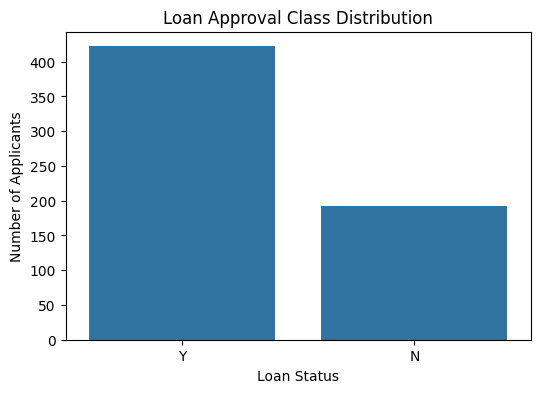

In [12]:

print(df['Loan_Status'].value_counts())

plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Loan_Status')

plt.title("Loan Approval Class Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")
plt.show()


In [13]:

df = df.drop('Loan_ID', axis=1)

print("Loan_ID column removed successfully!")
print(df.head())


Loan_ID column removed successfully!
  Gender Married Dependents     Education Self_Employed  ApplicantIncome  \
0   Male      No          0      Graduate            No             5849   
1   Male     Yes          1      Graduate            No             4583   
2   Male     Yes          0      Graduate           Yes             3000   
3   Male     Yes          0  Not Graduate            No             2583   
4   Male      No          0      Graduate            No             6000   

   CoapplicantIncome  LoanAmount  Loan_Amount_Term  Credit_History  \
0                0.0         NaN             360.0             1.0   
1             1508.0       128.0             360.0             1.0   
2                0.0        66.0             360.0             1.0   
3             2358.0       120.0             360.0             1.0   
4                0.0       141.0             360.0             1.0   

  Property_Area Loan_Status  
0         Urban           Y  
1         Rural          

In [14]:

X = df.drop('Loan_Status', axis=1)

y = df['Loan_Status'].map({
    'Y': 1,
    'N': 0
})

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())


Input Features:
  Gender Married Dependents     Education Self_Employed  ApplicantIncome  \
0   Male      No          0      Graduate            No             5849   
1   Male     Yes          1      Graduate            No             4583   
2   Male     Yes          0      Graduate           Yes             3000   
3   Male     Yes          0  Not Graduate            No             2583   
4   Male      No          0      Graduate            No             6000   

   CoapplicantIncome  LoanAmount  Loan_Amount_Term  Credit_History  \
0                0.0         NaN             360.0             1.0   
1             1508.0       128.0             360.0             1.0   
2                0.0        66.0             360.0             1.0   
3             2358.0       120.0             360.0             1.0   
4                0.0       141.0             360.0             1.0   

  Property_Area  
0         Urban  
1         Rural  
2         Urban  
3         Urban  
4         Urban 

In [15]:

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_features = X.select_dtypes(
    include=['object']
).columns

print("Numerical Features:")
print(list(numerical_features))

print("\nCategorical Features:")
print(list(categorical_features))


Numerical Features:
['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']

Categorical Features:
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']


In [16]:

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [17]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())


Training Records: 491
Testing Records: 123

Training Class Distribution:
Loan_Status
1    337
0    154
Name: count, dtype: int64

Testing Class Distribution:
Loan_Status
1    85
0    38
Name: count, dtype: int64


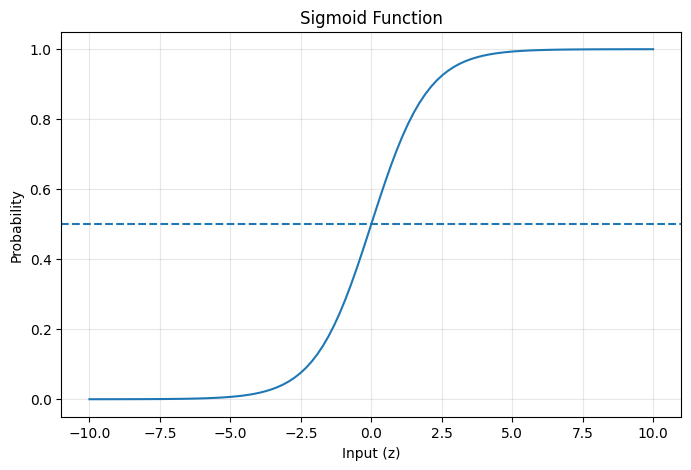

In [18]:

z = np.linspace(-10, 10, 100)

sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(8,5))

plt.plot(z, sigmoid)

plt.axhline(y=0.5, linestyle='--')

plt.title("Sigmoid Function")
plt.xlabel("Input (z)")
plt.ylabel("Probability")

plt.grid(alpha=0.3)
plt.show()


In [19]:

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")


Logistic Regression Model Trained Successfully!


In [20]:

classifier = model.named_steps['classifier']

feature_names = model.named_steps[
    'preprocessor'
].get_feature_names_out()

coefficients = classifier.coef_[0]

coefficient_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

print("Model Intercept:", classifier.intercept_[0])

print("\nFeature Coefficients:")
print(coefficient_df.sort_values(
    by='Coefficient',
    ascending=False
))


Model Intercept: 0.6324740721987615

Feature Coefficients:
                         Feature  Coefficient
4            num__Credit_History     1.247119
18  cat__Property_Area_Semiurban     0.463860
11             cat__Dependents_2     0.317990
8               cat__Married_Yes     0.276226
13       cat__Education_Graduate     0.192954
12            cat__Dependents_3+     0.135623
15         cat__Self_Employed_No     0.108466
5             cat__Gender_Female     0.091072
0           num__ApplicantIncome     0.011757
3          num__Loan_Amount_Term    -0.018088
2                num__LoanAmount    -0.042308
9              cat__Dependents_0    -0.067223
6               cat__Gender_Male    -0.091504
16        cat__Self_Employed_Yes    -0.108897
1         num__CoapplicantIncome    -0.148978
19      cat__Property_Area_Urban    -0.153065
14   cat__Education_Not Graduate    -0.193386
7                cat__Married_No    -0.276658
17      cat__Property_Area_Rural    -0.311226
10             cat__D

In [21]:

y_probability = model.predict_proba(X_test)[:, 1]

print("First 10 Predicted Probabilities:")
print(y_probability[:10])


First 10 Predicted Probabilities:
[0.05438961 0.89369698 0.7481669  0.71424476 0.88593037 0.82347533
 0.88364733 0.806942   0.70973016 0.74392582]


In [22]:

y_pred = (y_probability >= 0.5).astype(int)

print("Predicted Class Labels:")
print(y_pred[:10])


Predicted Class Labels:
[0 1 1 1 1 1 1 1 1 1]


In [23]:

comparison = pd.DataFrame({
    'Actual Loan Status': y_test.values,
    'Predicted Probability': y_probability,
    'Predicted Loan Status': y_pred
})

print(comparison.head(10))


   Actual Loan Status  Predicted Probability  Predicted Loan Status
0                   0               0.054390                      0
1                   1               0.893697                      1
2                   1               0.748167                      1
3                   1               0.714245                      1
4                   1               0.885930                      1
5                   0               0.823475                      1
6                   1               0.883647                      1
7                   1               0.806942                      1
8                   1               0.709730                      1
9                   1               0.743926                      1


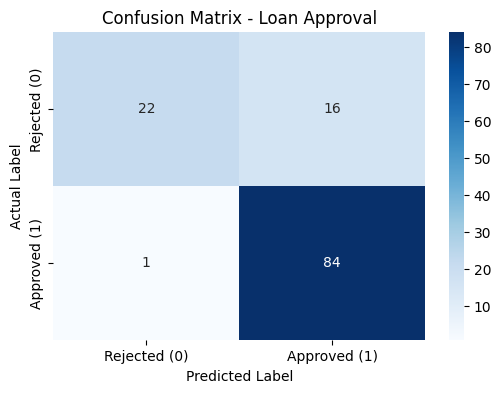

True Negative (TN): 22
False Positive (FP): 16
False Negative (FN): 1
True Positive (TP): 84


In [24]:

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Rejected (0)', 'Approved (1)'],
    yticklabels=['Rejected (0)', 'Approved (1)']
)

plt.title("Confusion Matrix - Loan Approval")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negative (TN):", tn)
print("False Positive (FP):", fp)
print("False Negative (FN):", fn)
print("True Positive (TP):", tp)


In [25]:

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, zero_division=0)

recall = recall_score(y_test, y_pred, zero_division=0)

specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

f1 = f1_score(y_test, y_pred, zero_division=0)

roc_auc = roc_auc_score(y_test, y_probability)

results = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'Specificity',
        'F1-Score',
        'ROC-AUC'
    ],
    'Score': [
        accuracy,
        precision,
        recall,
        specificity,
        f1,
        roc_auc
    ]
})

print(results)


        Metric     Score
0     Accuracy  0.861789
1    Precision  0.840000
2       Recall  0.988235
3  Specificity  0.578947
4     F1-Score  0.908108
5      ROC-AUC  0.852322


In [26]:

print("Classification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    target_names=['Rejected', 'Approved']
))


Classification Report:

              precision    recall  f1-score   support

    Rejected       0.96      0.58      0.72        38
    Approved       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



In [27]:

from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy='most_frequent')

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_pred)

print("Baseline Accuracy:", baseline_accuracy)

print("Logistic Regression Accuracy:", accuracy)


Baseline Accuracy: 0.6910569105691057
Logistic Regression Accuracy: 0.8617886178861789


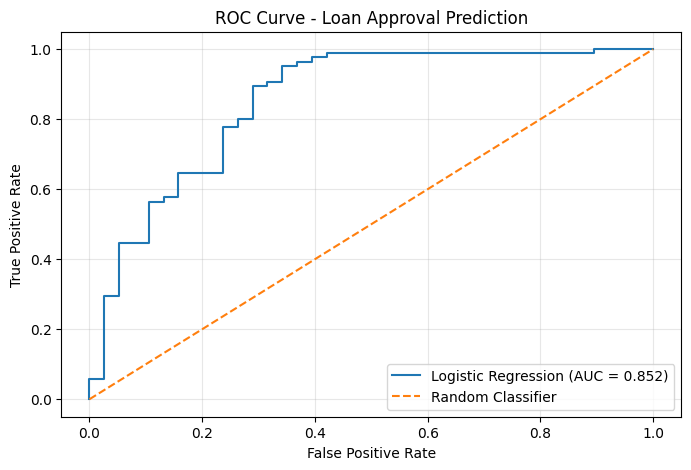

ROC-AUC Score: 0.8523219814241486


In [28]:

fpr, tpr, thresholds_roc = roc_curve(
    y_test,
    y_probability
)

plt.figure(figsize=(8,5))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {roc_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.title("ROC Curve - Loan Approval Prediction")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("ROC-AUC Score:", roc_auc)


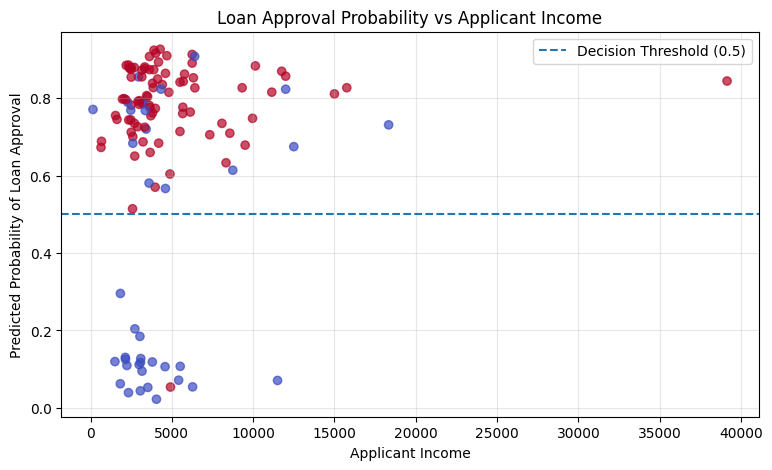

In [29]:

plt.figure(figsize=(9,5))

plt.scatter(
    X_test['ApplicantIncome'],
    y_probability,
    c=y_test,
    cmap='coolwarm',
    alpha=0.7
)

plt.axhline(
    y=0.5,
    linestyle='--',
    label='Decision Threshold (0.5)'
)

plt.title("Loan Approval Probability vs Applicant Income")
plt.xlabel("Applicant Income")
plt.ylabel("Predicted Probability of Loan Approval")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [30]:

train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, test_pred)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)


Training Accuracy: 0.8004073319755601
Testing Accuracy: 0.8617886178861789


In [31]:

new_applicant = pd.DataFrame([{
    'Gender': 'Male',
    'Married': 'Yes',
    'Dependents': '1',
    'Education': 'Graduate',
    'Self_Employed': 'No',
    'ApplicantIncome': 5000,
    'CoapplicantIncome': 2000,
    'LoanAmount': 150,
    'Loan_Amount_Term': 360,
    'Credit_History': 1.0,
    'Property_Area': 'Urban'
}])

new_probability = model.predict_proba(
    new_applicant
)[0][1]

new_prediction = int(new_probability >= 0.5)

print("Loan Approval Probability:", round(new_probability, 4))

if new_prediction == 1:
    print("Predicted Result: Loan Approved")
else:
    print("Predicted Result: Loan Rejected")


Loan Approval Probability: 0.7396
Predicted Result: Loan Approved


## Conclusion

In this activity, a Logistic Regression model was developed to predict loan approval using the Loan Prediction dataset. The dataset was inspected and preprocessed by handling missing values, encoding categorical variables and scaling numerical features.

The dataset was divided into training and testing sets using an 80:20 stratified split. The Logistic Regression model was trained to predict the probability of loan approval.

The model was evaluated using a confusion matrix, accuracy, precision, recall, specificity, F1-score and ROC-AUC. Its performance was also compared with a majority-class baseline. Different decision thresholds (0.3, 0.5 and 0.7) were analysed to understand the trade-off between precision and recall.

The experiment demonstrated how Logistic Regression performs binary classification and how decision thresholds influence predictions. The model provides probability-based estimates and should not be used as the sole basis for real-world loan approval decisions.